# Generische Augmentierungen

Interaktive Vorschau generischer Augmentierungen (Aufbau wie `04_parameter.ipynb`): Random Crop mit Box-Sicherheit,
Scale-Jitter, kleine affine Transformation, Mosaic, MixUp, Polaritätsumkehr sowie Helligkeit/Kontrast/Gamma.
GT-Boxen sind grün. Die Box-Parameter entsprechen `configs/template.yaml` (`min_visibility: 0.3`, `clip: true`).

In [1]:
%run 00_utils.ipynb

%load_ext autoreload
%autoreload 2

Root-Verzeichnis: /home/jessh/Study/Bachelor-Thesis
Datensätze: Anti-UAV410 + CST-AntiUAV


In [2]:
from pathlib import Path
import cv2, os
import numpy as np
import albumentations as A
from data_handler.dataset import AntiUAVDataset
from augmentations.uint8 import to_uint8

import matplotlib.pyplot as plt
import ipywidgets as widgets
from ipywidgets import interact, FloatSlider, IntSlider, FloatRangeSlider, Dropdown, Checkbox

In [3]:
# Trainings-Frames aller Datensätze in DATASETS (Reihenfolge wie in DATASETS).
# Nur einer: AntiUAVDataset(DatasetName.CST_ANTI_UAV, split="train", debug=True)
train_data = AntiUAVDataset(DATASETS, split="train", debug=True)

# Index-Bereich je Datensatz (für IMAGE_ID / train_data[...])
_start = 0
for ds in DATASETS:
    n = sum(r.dataset is ds for r in train_data.samples)
    print(f"{ds.value:<14} Index {_start} .. {_start + n - 1}")
    _start += n

# Indizes aller Frames mit Ziel (Quelle der Zusatzbilder für Mosaic / MixUp)
WITH_TARGET = [i for i, r in enumerate(train_data.samples) if r.bbox is not None]

25-11-2026 00:01:10 | INFO    | [train] Anti-UAV410: 213995 frames in 200 sequences (2.9 s)
25-11-2026 00:01:12 | INFO    | [train] CST-AntiUAV: 127991 frames in 120 sequences (2.2 s)


Anti-UAV410    Index 0 .. 213994
CST-AntiUAV    Index 213995 .. 341985


In [4]:
IMAGE_ID = 100000
sample = train_data.samples[IMAGE_ID]
_, _, img_org = train_data[IMAGE_ID]                            # Original, Graustufen uint8
gt_org = [sample.bbox] if sample.bbox is not None else []       # COCO: (x, y, w, h)
H, W = img_org.shape
print(f"{sample.dataset.value} / {sample.seq} / Frame {sample.frame_idx}: {W}×{H} px, Boxen: {gt_org}")

BBOX = dict(format="coco", label_fields=["class_labels"], min_visibility=0.3, clip=True)  # wie template.yaml
WIDE = {'description_width': 'initial'}   # volle Beschriftung anzeigen


def run(transforms, img=img_org, boxes=gt_org, seed=0, **extra):
    """Wendet die Transforms (Liste) mit festem Seed an; gibt (Bild, Boxen) zurück."""
    comp = A.Compose(transforms, bbox_params=A.BboxParams(**BBOX))
    comp.set_random_seed(seed)
    out = comp(image=img, bboxes=boxes, class_labels=[0] * len(boxes), **extra)
    return out["image"], [tuple(b) for b in out["bboxes"]]


def draw_boxes(ax, boxes, color="lime"):
    for x, y, w, h in boxes:
        ax.add_patch(plt.Rectangle((x - 2.5, y - 2.5), w + 4, h + 4, fill=False, ec=color, lw=1))


def zooms(img, boxes, pad=20):
    """Zoom auf jede Box (Box ± pad px)."""
    if not boxes:
        return
    _, axes = plt.subplots(1, len(boxes), figsize=(3 * len(boxes), 3), squeeze=False)
    for a, (x, y, w, h) in zip(axes[0], boxes):
        x0, y0 = max(int(x - pad), 0), max(int(y - pad), 0)
        a.imshow(img[y0:int(y + h + pad), x0:int(x + w + pad)], cmap="gray", vmin=0, vmax=255,
                 interpolation="nearest")
        a.set_title(f"{w:.1f}×{h:.1f} px", fontsize=9)
        a.axis("off")
    plt.show()


def visualise_spatial(img_aug, boxes_aug, img_in=img_org, boxes_in=gt_org):
    """Geometrische Transforms: Original und Ergebnis mit Boxen (Größe kann sich ändern), darunter Zooms."""
    print(f"Größe: {img_in.shape[1]}×{img_in.shape[0]} → {img_aug.shape[1]}×{img_aug.shape[0]} px   "
          f"Boxen: {len(boxes_in)} → {len(boxes_aug)}")
    _, ax = plt.subplots(1, 2, figsize=(16, 6.5))
    for a, im, bx, title in ((ax[0], img_in, boxes_in, "original"), (ax[1], img_aug, boxes_aug, "augmented")):
        a.imshow(im, cmap="gray", vmin=0, vmax=255)
        draw_boxes(a, bx)
        a.set_title(title)
        a.axis("off")
    plt.tight_layout()
    plt.show()
    zooms(img_aug, boxes_aug)


RAMP_U8 = np.arange(256, dtype=np.uint8)[None]   # alle Grauwerte als 1×256-Bild: ergibt die Kennlinie


def visualise_point(transforms, seed=0):
    """Punktoperationen: Original, Ergebnis, Differenz und Kennlinie (Ausgabe- über Eingabegrauwert)."""
    img_aug, _ = run(transforms, seed=seed)
    curve, _ = run(transforms, img=RAMP_U8, boxes=[], seed=seed)

    _, ax = plt.subplots(1, 4, figsize=(20, 5))
    ax[0].imshow(img_org, cmap="gray", vmin=0, vmax=255); ax[0].set_title("original")
    ax[1].imshow(img_aug, cmap="gray", vmin=0, vmax=255); ax[1].set_title("augmented")
    ax[2].imshow(img_aug.astype(np.float32) - img_org.astype(np.float32), cmap="seismic", vmin=-255, vmax=255)
    ax[2].set_title("difference")
    for a in ax[:3]:
        draw_boxes(a, gt_org)
        a.axis("off")
    ax[3].plot(RAMP_U8[0], RAMP_U8[0], "k--", lw=0.8, label="Identität")
    ax[3].plot(RAMP_U8[0], curve[0], lw=1.5, label="Transform")
    ax[3].set(xlim=(0, 255), ylim=(0, 255), xlabel="Eingang", ylabel="Ausgang", title="Kennlinie", aspect="equal")
    ax[3].legend(loc="upper left")
    plt.tight_layout()
    plt.show()
    zooms(img_aug, gt_org)


def fill_value(name, img=img_org):
    return {"Bildmittel": float(img.mean()), "0 (schwarz)": 0, "255 (weiß)": 255}[name]

Anti-UAV410 / 20190926_130341_1_4 / Frame 847: 640×512 px, Boxen: [(303.0, 287.0, 70.0, 37.0)]


## Random Crop mit Box-Sicherheit

Drei Albumentations-Varianten:
- `BBoxSafeRandomCrop`: zufälliger Ausschnitt, der **alle** Boxen enthält; keine Skalierung, die Bildgröße ändert sich
  (im Training skaliert `LetterBox` danach wieder auf `imgsz`, das wirkt also wie ein Zoom).
- `RandomSizedBBoxSafeCrop`: wie oben, danach zurück auf 640×512 skaliert (expliziter Zoom).
- `AtLeastOneBBoxRandomCrop`: Ausschnitt fester Größe (`crop height/width`), der mindestens eine Box enthält.

`erosion` lässt zu, dass ein Teil der Box abgeschnitten wird (Anteil der Boxgröße). Ohne Box im Frame entsteht ein
beliebiger zufälliger Ausschnitt.

In [5]:
def explore(seed=0, variant="BBoxSafeRandomCrop", erosion=0.0, crop_h=256, crop_w=320):
    t = {
        "BBoxSafeRandomCrop":      lambda: A.BBoxSafeRandomCrop(erosion_rate=erosion, p=1.0),
        "RandomSizedBBoxSafeCrop": lambda: A.RandomSizedBBoxSafeCrop(height=H, width=W, erosion_rate=erosion, p=1.0),
        "AtLeastOneBBoxRandomCrop": lambda: A.AtLeastOneBBoxRandomCrop(height=crop_h, width=crop_w,
                                                                        erosion_factor=erosion, p=1.0),
    }[variant]()
    visualise_spatial(*run([t], seed=seed))


interact(
    explore,
    seed    = IntSlider(min=0, max=200, step=1, value=0, continuous_update=False, style=WIDE),
    variant = Dropdown(options=["BBoxSafeRandomCrop", "RandomSizedBBoxSafeCrop", "AtLeastOneBBoxRandomCrop"],
                       value="BBoxSafeRandomCrop", description="variant"),
    erosion = FloatSlider(min=0.0, max=0.9, step=0.05, value=0.0, continuous_update=False, style=WIDE,
                          description='erosion'),
    crop_h  = IntSlider(min=64, max=H, step=32, value=256, continuous_update=False, style=WIDE,
                        description='crop height (AtLeastOne)'),
    crop_w  = IntSlider(min=64, max=W, step=32, value=320, continuous_update=False, style=WIDE,
                        description='crop width (AtLeastOne)'),
);

interactive(children=(IntSlider(value=0, continuous_update=False, description='seed', max=200, style=SliderSty…

## Random Scale / Resize-Jitter (Multi-Scale)

`RandomScale` skaliert Bild und Boxen um einen Faktor aus `1 + scale_limit` (die Bildgröße ändert sich).
**Achtung:** Im Training skaliert `LetterBox` jedes Bild wieder auf `imgsz`, ein reines Resize wäre damit (bis auf
Interpolationsverluste) rückgängig gemacht. Mit `fester Rahmen` wird das Ergebnis deshalb auf 640×512 gebracht:
kleiner → mit `fill` aufgefüllt (zufällige Position), größer → Ausschnitt fester Größe mit mindestens einer Box
(`AtLeastOneBBoxRandomCrop`). Erst so ändert sich die Objektgröße im Netz-Eingang. (Ultralytics' eigenes `multi_scale`
ändert stattdessen `imgsz` pro Batch; es ist wie alle Ultralytics-Augmentierungen aus.)

In [6]:
def explore(seed=0, scale_limit=(-0.3, 0.3), fixed_canvas=True, fill="Bildmittel", interpolation="linear"):
    interp = {"nearest": cv2.INTER_NEAREST, "linear": cv2.INTER_LINEAR, "area": cv2.INTER_AREA,
              "cubic": cv2.INTER_CUBIC}[interpolation]
    ts = [A.RandomScale(scale_limit=tuple(scale_limit), interpolation=interp, p=1.0)]
    if fixed_canvas:
        ts += [A.PadIfNeeded(min_height=H, min_width=W, position="random", border_mode=cv2.BORDER_CONSTANT,
                             fill=fill_value(fill), p=1.0),
               A.AtLeastOneBBoxRandomCrop(height=H, width=W, p=1.0)]
    visualise_spatial(*run(ts, seed=seed))


interact(
    explore,
    seed          = IntSlider(min=0, max=200, step=1, value=0, continuous_update=False, style=WIDE),
    scale_limit   = FloatRangeSlider(min=-0.9, max=1.0, step=0.05, value=(-0.3, 0.3), continuous_update=False,
                                     style=WIDE, description='scale_limit (Faktor = 1 + Wert)'),
    fixed_canvas  = Checkbox(value=True, description='fester Rahmen 640×512'),
    fill          = Dropdown(options=["Bildmittel", "0 (schwarz)", "255 (weiß)"], value="Bildmittel",
                             description='fill'),
    interpolation = Dropdown(options=["nearest", "linear", "area", "cubic"], value="linear",
                             description='interpolation'),
);

interactive(children=(IntSlider(value=0, continuous_update=False, description='seed', max=200, style=SliderSty…

## Kleine affine Transformation

`A.Affine` mit kleinen Werten: Skalierung, Verschiebung (Anteil der Bildgröße), Rotation und Scherung, jeweils
symmetrisch um 0 bzw. 1 gezogen. Die Bildgröße bleibt 640×512; leere Bereiche werden mit `fill` gefüllt.
Bei Rotation wird die Box neu umschlossen (`rotate_method`: `largest_box` = Box der gedrehten Ecken, wird größer;
`ellipse` = Box der gedrehten eingeschriebenen Ellipse, enger).

In [7]:
def explore(seed=0, scale=0.1, translate=0.05, rotate=5.0, shear=2.0, rotate_method="largest_box",
            fill="Bildmittel"):
    t = A.Affine(scale=(1 - scale, 1 + scale), translate_percent=(-translate, translate), rotate=(-rotate, rotate),
                 shear=(-shear, shear), rotate_method=rotate_method, border_mode=cv2.BORDER_CONSTANT,
                 fill=fill_value(fill), p=1.0)
    visualise_spatial(*run([t], seed=seed))


interact(
    explore,
    seed          = IntSlider(min=0, max=200, step=1, value=0, continuous_update=False, style=WIDE),
    scale         = FloatSlider(min=0.0, max=0.5, step=0.05, value=0.1, continuous_update=False, style=WIDE,
                                description='scale ± (Anteil)'),
    translate     = FloatSlider(min=0.0, max=0.3, step=0.01, value=0.05, continuous_update=False, style=WIDE,
                                description='translate ± (Anteil)'),
    rotate        = FloatSlider(min=0.0, max=30.0, step=1.0, value=5.0, continuous_update=False, style=WIDE,
                                description='rotate ± (°)'),
    shear         = FloatSlider(min=0.0, max=20.0, step=1.0, value=2.0, continuous_update=False, style=WIDE,
                                description='shear ± (°)'),
    rotate_method = Dropdown(options=["largest_box", "ellipse"], value="largest_box", description='rotate_method'),
    fill          = Dropdown(options=["Bildmittel", "0 (schwarz)", "255 (weiß)"], value="Bildmittel",
                             description='fill'),
);

interactive(children=(IntSlider(value=0, continuous_update=False, description='seed', max=200, style=SliderSty…

## Mosaic

`A.Mosaic` setzt den Frame `IMAGE_ID` und drei weitere zufällige Train-Frames (mit `seed` gewählt; `nur mit Ziel` =
nur Frames mit Box) in ein 2×2-Raster aus Zellen der Größe `cell scale` × 640×512. Daraus wird ein 640×512-Ausschnitt
genommen, dessen Mitte über `center_range` gezogen wird. `cell scale` < 1 verkleinert die Bilder (und Ziele),
`fit_mode` legt fest, wie ein Bild in die Zelle gebracht wird (`cover` = füllen und beschneiden, `contain` = ganz
einpassen und auffüllen). Rechts die vier Quellbilder.

In [8]:
def random_frames(n, seed, with_target=True):
    """n zufällige Train-Frames (Bild + COCO-Boxen), reproduzierbar über seed."""
    rng = np.random.default_rng(seed)
    pool = WITH_TARGET if with_target else range(len(train_data))
    out = []
    for i in rng.choice(pool, size=n, replace=False):
        r = train_data.samples[int(i)]
        out.append({"image": train_data[int(i)][2],
                    "bboxes": np.array([r.bbox] if r.bbox is not None else [], dtype=np.float32).reshape(-1, 4),
                    "class_labels": [0] if r.bbox is not None else []})
    return out


def explore(seed=0, with_target=True, cell_scale=1.0, center_range=(0.3, 0.7), fit_mode="cover", fill="Bildmittel"):
    extra = random_frames(3, seed, with_target)
    cell = (int(H * cell_scale), int(W * cell_scale))
    t = A.Mosaic(grid_yx=(2, 2), target_size=(H, W), cell_shape=cell, center_range=tuple(center_range),
                 fit_mode=fit_mode, fill=fill_value(fill), p=1.0)
    img, boxes = run([t], seed=seed, mosaic_metadata=extra)

    print(f"Boxen im Mosaic: {len(boxes)} (Quellen: {len(gt_org) + sum(len(m['bboxes']) for m in extra)})")
    fig = plt.figure(figsize=(20, 7))
    gs = fig.add_gridspec(2, 4)
    a = fig.add_subplot(gs[:, :2])
    a.imshow(img, cmap="gray", vmin=0, vmax=255); draw_boxes(a, boxes); a.set_title("Mosaic"); a.axis("off")
    sources = [{"image": img_org, "bboxes": gt_org}] + extra
    for k, m in enumerate(sources):
        a = fig.add_subplot(gs[k // 2, 2 + k % 2])
        a.imshow(m["image"], cmap="gray", vmin=0, vmax=255); draw_boxes(a, m["bboxes"])
        a.set_title("IMAGE_ID" if k == 0 else f"Zusatzbild {k}", fontsize=9); a.axis("off")
    plt.tight_layout()
    plt.show()
    zooms(img, boxes)


interact(
    explore,
    seed         = IntSlider(min=0, max=200, step=1, value=0, continuous_update=False, style=WIDE),
    with_target  = Checkbox(value=True, description='nur mit Ziel'),
    cell_scale   = FloatSlider(min=0.25, max=1.0, step=0.05, value=1.0, continuous_update=False, style=WIDE,
                               description='cell scale'),
    center_range = FloatRangeSlider(min=0.0, max=1.0, step=0.05, value=(0.3, 0.7), continuous_update=False,
                                    style=WIDE, description='center_range'),
    fit_mode     = Dropdown(options=["cover", "contain"], value="cover", description='fit_mode'),
    fill         = Dropdown(options=["Bildmittel", "0 (schwarz)", "255 (weiß)"], value="Bildmittel",
                            description='fill'),
);

interactive(children=(IntSlider(value=0, continuous_update=False, description='seed', max=200, style=SliderSty…

## MixUp

Albumentations 2.0.8 hat kein MixUp; `mixup` unten ist eine kleine Umsetzung nur für dieses Notebook (nicht in
`src/`): I = λ·I₁ + (1 − λ)·I₂ mit λ ~ Beta(α, α), Boxen = Vereinigung beider Bilder (Zhang et al. 2018, für
Detektion Zhang et al. 2019 „Bag of Freebies“; YOLOv4/Ultralytics nutzen α = 32, also λ ≈ 0.5). Kleines α → λ
meist nahe 0 oder 1 (ein Bild dominiert). Mit `festes λ` wird λ direkt gesetzt. I₂ ist ein zufälliger Train-Frame.
Beide Bilder haben 640×512, daher ist kein Resize nötig.

In [9]:
def mixup(img1, boxes1, img2, boxes2, lam):
    """Gewichtetes Mittel zweier gleich großer uint8-Bilder; Boxen beider Bilder bleiben erhalten."""
    out = to_uint8(lam * img1.astype(np.float32) + (1 - lam) * img2.astype(np.float32))
    return out, list(boxes1) + [tuple(b) for b in boxes2]


def explore(seed=0, alpha=32.0, fixed=False, lam_fixed=0.5, with_target=True):
    other = random_frames(1, seed, with_target)[0]
    lam = lam_fixed if fixed else float(np.random.default_rng(seed).beta(alpha, alpha))
    img, boxes = mixup(img_org, gt_org, other["image"], other["bboxes"], lam)

    print(f"λ = {lam:.3f}   Boxen: {len(gt_org)} + {len(other['bboxes'])}")
    _, ax = plt.subplots(1, 3, figsize=(20, 5.5))
    for a, im, bx, title in ((ax[0], img_org, gt_org, "I₁ (IMAGE_ID)"),
                             (ax[1], other["image"], other["bboxes"], "I₂"),
                             (ax[2], img, boxes, f"MixUp, λ = {lam:.2f}")):
        a.imshow(im, cmap="gray", vmin=0, vmax=255); draw_boxes(a, bx); a.set_title(title); a.axis("off")
    plt.tight_layout()
    plt.show()
    zooms(img, boxes)


interact(
    explore,
    seed        = IntSlider(min=0, max=200, step=1, value=0, continuous_update=False, style=WIDE),
    alpha       = FloatSlider(min=0.1, max=64.0, step=0.1, value=32.0, continuous_update=False, style=WIDE,
                              description='alpha (Beta)'),
    fixed       = Checkbox(value=False, description='festes λ'),
    lam_fixed   = FloatSlider(min=0.0, max=1.0, step=0.05, value=0.5, continuous_update=False, style=WIDE,
                              description='λ (fest)'),
    with_target = Checkbox(value=True, description='I₂ nur mit Ziel'),
);

interactive(children=(IntSlider(value=0, continuous_update=False, description='seed', max=200, style=SliderSty…

## Polaritätsumkehr

`A.InvertImg`: I' = 255 − I, also White-hot ↔ Black-hot (eine Einstellung vieler Wärmebildkameras). Ein warmes
Ziel wird dunkel vor hellerem Hintergrund. Keine Parameter.

/home/jessh/Study/Bachelor-Thesis/.venv/lib/python3.10/site-packages/albumentations/core/composition.py:331: UserWarning: Got processor for bboxes, but no transform to process it.
  self._set_keys()


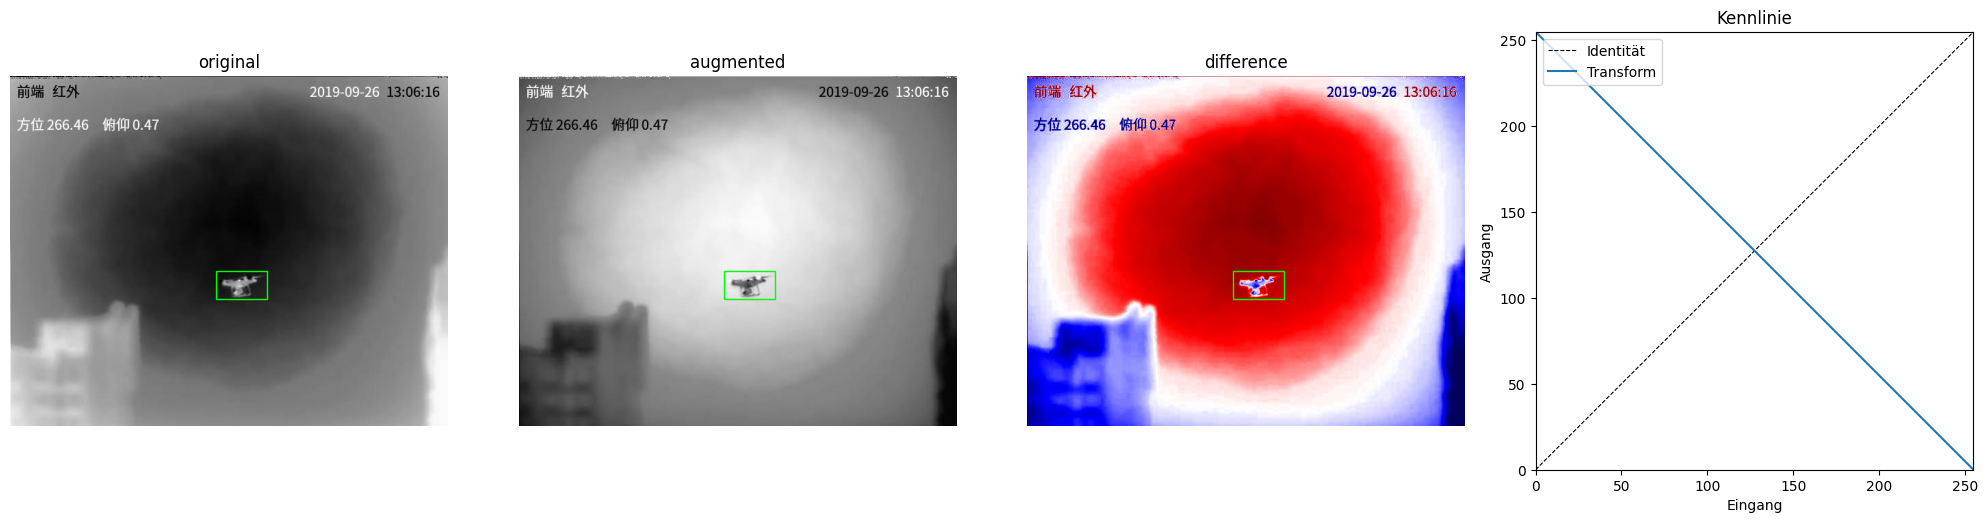

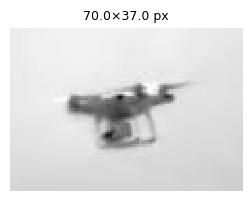

In [10]:
visualise_point([A.InvertImg(p=1.0)])

## Helligkeit, Kontrast und Gamma

`A.RandomBrightnessContrast` und `A.RandomGamma` mit festem Wert (unteres = oberes Limit), damit der Effekt genau
eines Werts zu sehen ist; im Training wird aus dem Bereich ±Wert gezogen. Helligkeit β und Kontrast α:
I' = α·I + β·max (bei `brightness_by_max`, sonst β·Bildmittel), α = 1 + contrast. Gamma: I' = 255·(I/255)^γ,
γ = gamma/100 (> 100 dunkler, < 100 heller). Die Kennlinie rechts zeigt Ausgabe über Eingabegrauwert; Werte
außerhalb [0, 255] werden abgeschnitten (Sättigung).

In [11]:
def explore(brightness=0.0, contrast=0.0, brightness_by_max=True, gamma=100):
    visualise_point([
        A.RandomBrightnessContrast(brightness_limit=(brightness, brightness), contrast_limit=(contrast, contrast),
                                   brightness_by_max=brightness_by_max, p=1.0),
        A.RandomGamma(gamma_limit=(gamma, gamma), p=1.0),
    ])


interact(
    explore,
    brightness        = FloatSlider(min=-0.5, max=0.5, step=0.02, value=0.0, continuous_update=False, style=WIDE,
                                    description='brightness β'),
    contrast          = FloatSlider(min=-0.5, max=0.5, step=0.02, value=0.0, continuous_update=False, style=WIDE,
                                    description='contrast (α = 1 + Wert)'),
    brightness_by_max = Checkbox(value=True, description='brightness_by_max'),
    gamma             = IntSlider(min=40, max=250, step=5, value=100, continuous_update=False, style=WIDE,
                                  description='gamma (γ = Wert/100)'),
);

interactive(children=(FloatSlider(value=0.0, continuous_update=False, description='brightness β', max=0.5, min…